<div style="text-align: center; background: white; padding: 10px; display: inline-block; width: 100%;">
    <img src="logo_cc.png" width="400">
</div>

## Introduction (Exploratory Data Analysis) :
This project is a professional collaboration with `Ora Technologies` to build a machine learning model for their money-transferring application , `Ora Cash`. The primary goal is to predict user churn and identify at-risk users who are likely to delete their accounts. By understanding the factors contributing to churn, we aim to provide actionable insights to prevent account deletions and increase user activity on the app.

`Ora Cash` is a financial application that allows users to transfer money seamlessly. However, like many subscription-based services, retaining users is a critical challenge. Users may delete their accounts for various reasons, including: Dissatisfaction with the service , Switching to a competitor , No longer needing the service.

To address this, we will analyze `user` behavior and `transaction` data to identify patterns and features that contribute to churn. The insights derived from this analysis will help Ora Technologies implement targeted interventions to retain users and enhance their engagement with the app.

### Project Goals
The key objectives of this project are:
1. Build a predictive model to identify users at risk of churning.
2. Analyze and visualize important features contributing to churn.
3. Provide actionable insights to help Ora Technologies:
    - Retain at-risk users by implementing targeted interventions.
    - Increase user activity and engagement on the Ora Cash application.

By achieving these goals, we aim to enhance user retention and drive growth for Ora Technologies.

## Understanding the Datasets

### Dataset descriptions
For this project, we are working with two datasets provided by Ora Technologies : (1) a `users` dataset containing profile information (e.g., creation date, last activity, account deletion status) and (2) a `transactions` dataset recording all financial interactions (e.g., payment timestamps, amounts, methods) within Ora Cash application. The goal is to merge these datasets to analyze user behavior and predict churn—whether a user will delete their account in the future. By engineering features like transaction frequency, spending trends, and inactivity periods, we’ll build a model to identify at-risk users before they churn.

In [2]:
import pandas as pd
pd.set_option('display.max_colwidth', None)

In [3]:
# Users dataset description
users_descriptions = pd.read_csv("Users_descriptions.csv")
users_descriptions.style.set_properties(**{'text-align': 'left'})

,Column_Name,Description
0,User_Id,Unique identifier for the user
1,Phone_Number,User's phone number for authentication and contact
2,User_Type,"Type of user (CUSTOMER, MERCHANT)"
3,Gender,"User's gender (male, female)"
4,Created_At,Timestamp when the user account was created
5,Updated_At,Timestamp when the user account was last updated
6,Deleted_At,Timestamp when the user account was deleted (soft delete)
7,First_Name,User's first name
8,Last_Online,Timestamp when the user was last online
9,Is_Online,Boolean indicating if the user is currently online


In [4]:
# Transactions dataset description
transactions_descriptions = pd.read_csv("Transactions_descriptions.csv")
transactions_descriptions.style.set_properties(**{'text-align': 'left'})

,Column_Name,Description
0,User_Id,Unique identifier for the user
1,Phone_Number,Phone number associated with the account
2,Arn,Acquirer Reference Number (unique transaction ID)
3,Amount,Transaction amount (in DH)
4,Date_transaction,Date when the transaction occurred (YYYY-MM-DD format)
5,Time,Time when the transaction occurred (HH:MM:SS format)
6,Type_transaction,"Type of transaction (e.g., CASH IN EN MASSE, CASH IN, WALLET_TO_WALLET_CREDIT)"
7,Signature,"Transaction signature (C = Credit, D = Debit)"
8,First_Name,First name of the account holder


## Import Python Modules

First, we need to import the primary modules that will be used in this EDA like :
- pandas
- numpy
- maplotlib
- seaborn
- sklearn
- etc

In [5]:
# Import required packages

# Data packages
import pandas as pd
import numpy as np

# Visualization Packages
from matplotlib import pyplot as plt
import seaborn as sns
import plotly.express as px
%matplotlib inline

In [6]:
# importing OneHotEncoder for categorical encoding
from sklearn.preprocessing import OneHotEncoder

## Load the Data

We start by loading the excel file `FinalDBOraCash.xlsx` into two dataframes `users`, and `transactions` and display the shape of them.

In [7]:
#Loading users
users = pd.read_excel('FinalDBOraCash.xlsx', sheet_name='UserOraCash_anonyme')
print('users Shape:', users.shape)
users.head()

users Shape: (13203, 16)


,id,phoneNumber,userType,gender,createdAt,updatedAt,deletedAt,firstName,lastOnline,isOnline,avatar,mustPayMonthlyFee,enableMessagesNotification,enableTransactionsNotification,language,walletType
0,d08cfe7e-a2ed-4fdf-8ebb-f2104b1bf657,212601705767,CUSTOMER,MALE,2025-01-25 22:20:53.566,2025-01-25 22:24:54.162,NaT,EL MUSTAPHA,2025-01-25 22:24:54.141,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",f,t,t,en,WALLET_200
1,f5a9d798-00e0-4c6c-ae41-56e8c2b29b47,212634201652,CUSTOMER,MALE,2025-03-02 04:14:34.529,2025-03-02 04:17:13.600,NaT,TAOUFIK,2025-03-02 04:17:13.576,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg""}",f,t,t,ar-FR,WALLET_200
2,27ee6b57-8043-4aae-9fdf-9e07b2862b34,212620225129,CUSTOMER,MALE,2025-01-22 07:11:10.252,2025-01-26 22:57:49.909,NaT,Bilal,2025-01-26 22:57:49.873,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg""}",f,t,t,en,WALLET_200
3,cf72657e-4a71-4a05-9dfb-ac15d95fbfa9,212674197653,CUSTOMER,FEMALE,2024-11-19 14:33:57.428,2024-11-19 14:58:56.101,NaT,Amina,2024-11-19 14:58:56.074,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg""}",f,t,t,fr,WALLET_20000
4,458d9f2b-c65c-4ec5-8c50-02f1ddf7eb15,212689323565,CUSTOMER,MALE,2025-01-18 21:23:50.171,2025-01-19 14:38:28.732,NaT,WaliD,2025-01-19 14:38:28.708,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",f,t,t,ar,WALLET_200


In [8]:
#Loading transactions
transactions = pd.read_excel('FinalDBOraCash.xlsx', sheet_name='TransRec_anonyme')
print('transactions Shape:', transactions.shape)
transactions.head()

transactions Shape: (2678, 9)


,User Id,num_phone,arn,montant,date_transaction,Time,type_transaction,sig,prenom
0,NaN,NaN,7.111111e+22,1.0,2024-11-13,18:19:46,CASH IN EN MASSE,C,ASMAA
1,NaN,NaN,7.111111e+22,33.0,2024-11-13,19:50:55,CASH IN,C,ASMAA
2,6ee30034-01a4-4f12-853f-d23df6e9f6b4,2.126004e+11,7.111111e+22,150.0,2024-11-14,16:14:06,WALLET_TO_WALLET_CREDIT,C,AYOUB
3,6ee30034-01a4-4f12-853f-d23df6e9f6b4,2.126004e+11,7.111111e+22,433.0,2024-11-15,11:15:32,WALLET_TO_WALLET_DEBIT,D,AYOUB
4,5e9b6917-572b-400c-a249-4d90e644ac28,2.126548e+11,7.111111e+22,10.0,2024-11-15,16:18:02,PAIMENT_FACTURE,D,mohammed


## Data Exploration and Cleaning:

The data cleaning phase involves standardizing raw datasets (users and transactions) by handling missing values, correcting inconsistent formats (e.g., phone numbers, dates), validating categorical fields (e.g., transaction types), and removing duplicates or invalid entries.

In [9]:
#Checking for missing values in users
print('Missing values in users:')
users.isnull().sum()

Missing values in users:


id                                    0
phoneNumber                           0
userType                              0
gender                              118
createdAt                             0
updatedAt                             0
deletedAt                         12349
firstName                             0
lastOnline                            0
isOnline                              0
avatar                              347
mustPayMonthlyFee                     0
enableMessagesNotification            0
enableTransactionsNotification        0
language                              0
walletType                            0
dtype: int64

In [10]:
#Checking for missing values in transactions
print('Missing values in transactions:')
transactions.isnull().sum()

Missing values in transactions:


User Id              84
num_phone            84
arn                   0
montant               0
date_transaction      0
Time                  0
type_transaction      0
sig                 224
prenom              224
dtype: int64

In [11]:
# Extract the first four digits of the phone numbers
Phone_Prefix = users['phoneNumber'].astype(str).str[:4]

# Count the occurrences of each prefix
Phone_Prefix.value_counts()

phoneNumber
2126    13203
Name: count, dtype: int64

- The phone prefix has one unique value, so we can't extract more informations from phone numbers.

In [12]:
def clean_users(df):
    # Rename columns based on descriptions
    df.columns = users_descriptions["Column_Name"].values

    # Handle duplicates
    df = df.drop_duplicates(subset=['User_Id'])
    
    # Process the First_Name column in users_clean
    df['First_Name'] = df['First_Name'].str.lower()
    
    # Validate user IDs
    df = df[df['User_Id'].notna()]
    
    # Delete Phone_Number column
    df = df.drop(['Phone_Number'], axis=1)
    
    # Delete is_online column
    df = df.drop(['Is_Online'], axis=1)
    # Handle NaN values
    df['Gender'] = df['Gender'].fillna('Unknown')
    df['Deleted_At'] = df['Deleted_At'].fillna(pd.NaT)
    df['Avatar'] = df['Avatar'].fillna('No Avatar')
    return df

In [13]:
def clean_transactions(df):
    # Rename columns based on descriptions
    df.columns = transactions_descriptions["Column_Name"].values
    
    
    # Handle monetary values
    df['Amount'] = pd.to_numeric(df['Amount'], errors='coerce')
    df = df[df['Amount'] > 0]  # Remove negative amounts
    
    # Clean categoricals
    df['Signature'] = df['Signature'].str.upper().replace(['C','D'], ['Credit','Debit'])
    df['Type_transaction'] = df['Type_transaction'].str.lower().str.strip()
    
    

    # Process the First_Name column in transactions_clean
    df['First_Name'] = df['First_Name'].str.lower()
    df['First_Name'] = df['First_Name'].str.replace(' ', '')
    # Delete ARNs
    df = df.drop(['Arn'], axis = 1)

    # Delete Phone_Number column
    df = df.drop(['Phone_Number'], axis=1)
    
    # Handle missing values
    df['User_Id'] = df['User_Id'].fillna('Unknown')  # Replace missing User_Id with 'Unknown'
    df['Signature'] = df['Signature'].fillna('Unknown')  # Replace missing Sig with 'Unknown'
    df['First_Name'] = df['First_Name'].fillna('No Name')  # Replace missing First_Name with 'No Name'
    
    return df

In [14]:
# Apply cleaning
users_clean = clean_users(users)
transactions_clean = clean_transactions(transactions)

In [15]:
users_clean.head()

,User_Id,User_Type,Gender,Created_At,Updated_At,Deleted_At,First_Name,Last_Online,Avatar,Must_Pay_Monthly_Fee,Enable_Messages_Notification,Enable_Transactions_Notification,Language,Wallet_Type
0,d08cfe7e-a2ed-4fdf-8ebb-f2104b1bf657,CUSTOMER,MALE,2025-01-25 22:20:53.566,2025-01-25 22:24:54.162,NaT,el mustapha,2025-01-25 22:24:54.141,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",f,t,t,en,WALLET_200
1,f5a9d798-00e0-4c6c-ae41-56e8c2b29b47,CUSTOMER,MALE,2025-03-02 04:14:34.529,2025-03-02 04:17:13.600,NaT,taoufik,2025-03-02 04:17:13.576,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg""}",f,t,t,ar-FR,WALLET_200
2,27ee6b57-8043-4aae-9fdf-9e07b2862b34,CUSTOMER,MALE,2025-01-22 07:11:10.252,2025-01-26 22:57:49.909,NaT,bilal,2025-01-26 22:57:49.873,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg""}",f,t,t,en,WALLET_200
3,cf72657e-4a71-4a05-9dfb-ac15d95fbfa9,CUSTOMER,FEMALE,2024-11-19 14:33:57.428,2024-11-19 14:58:56.101,NaT,amina,2024-11-19 14:58:56.074,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg""}",f,t,t,fr,WALLET_20000
4,458d9f2b-c65c-4ec5-8c50-02f1ddf7eb15,CUSTOMER,MALE,2025-01-18 21:23:50.171,2025-01-19 14:38:28.732,NaT,walid,2025-01-19 14:38:28.708,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",f,t,t,ar,WALLET_200


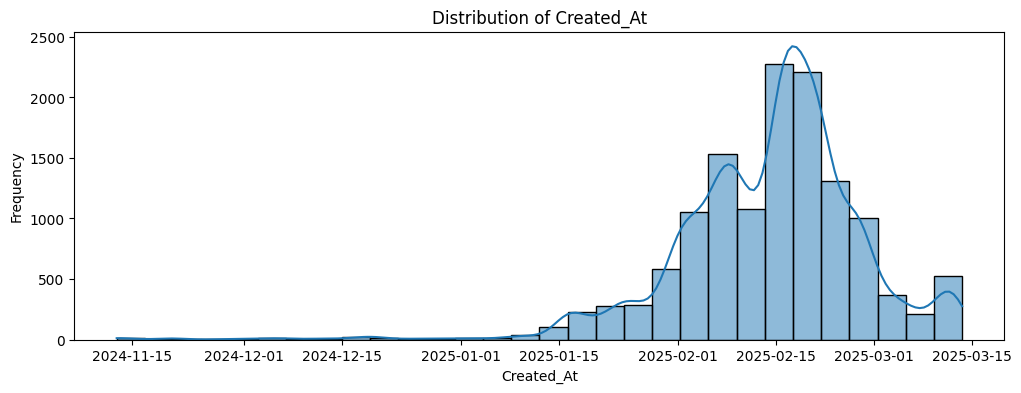

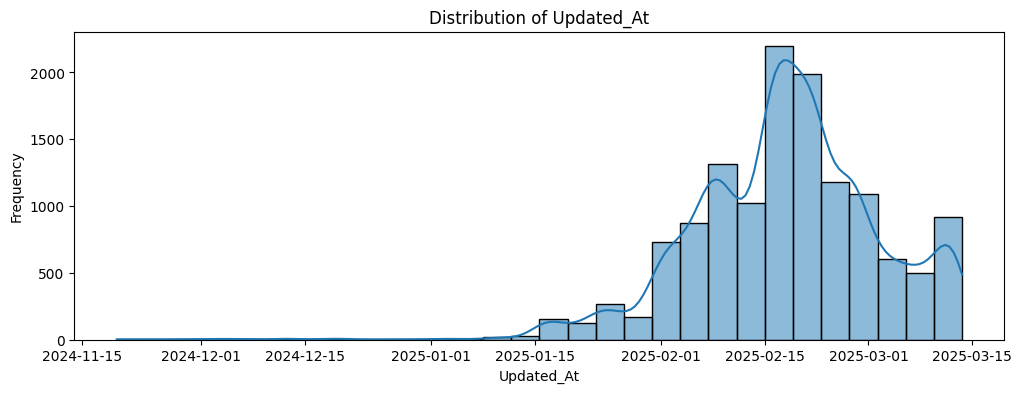

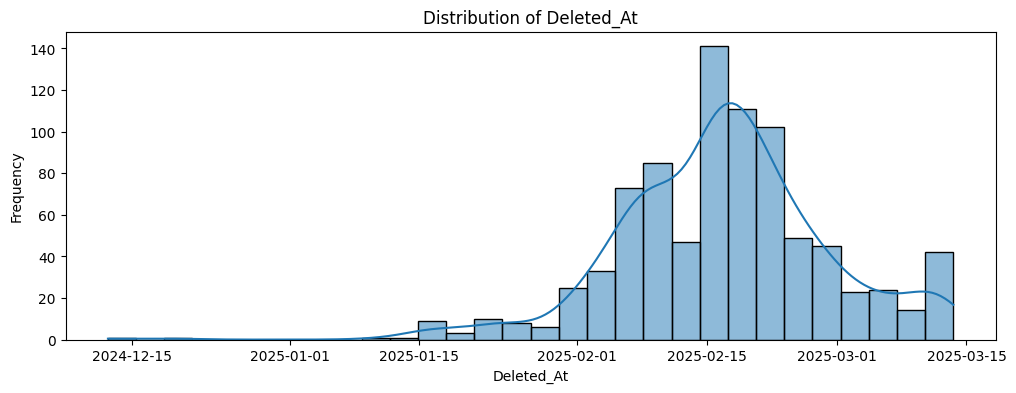

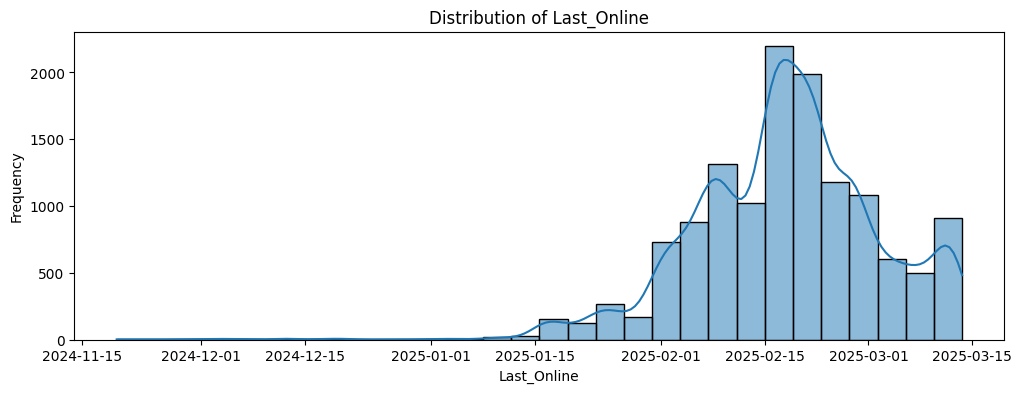

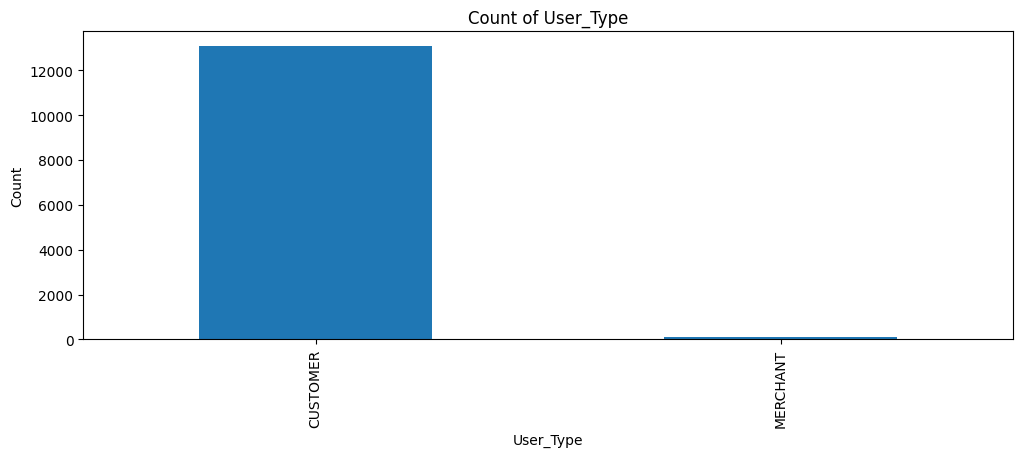

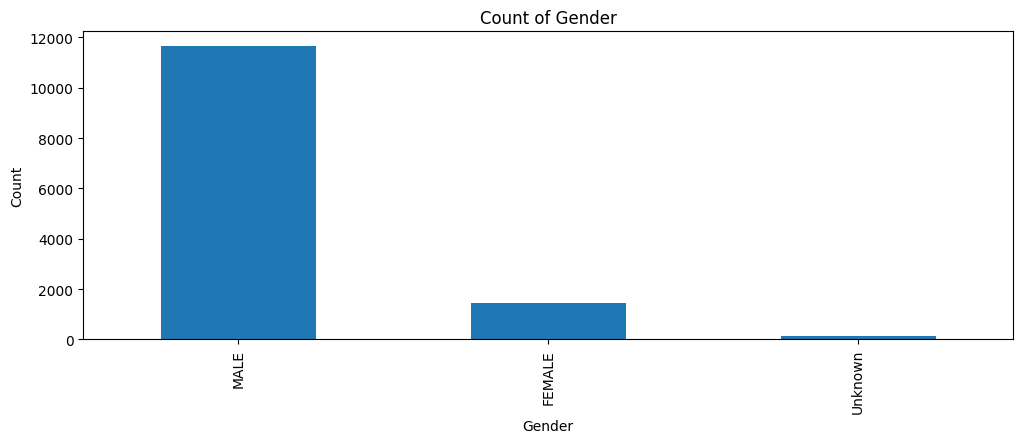

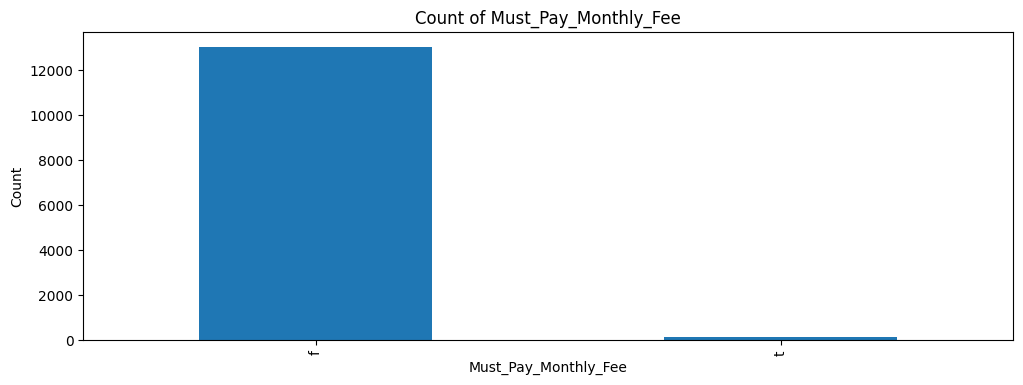

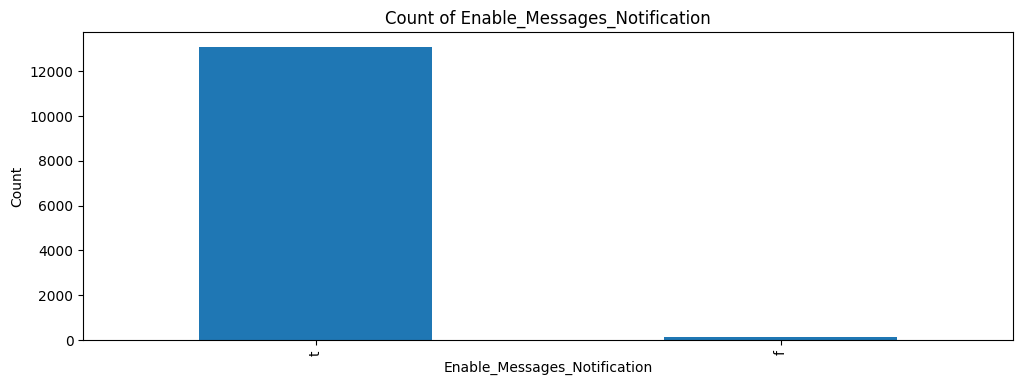

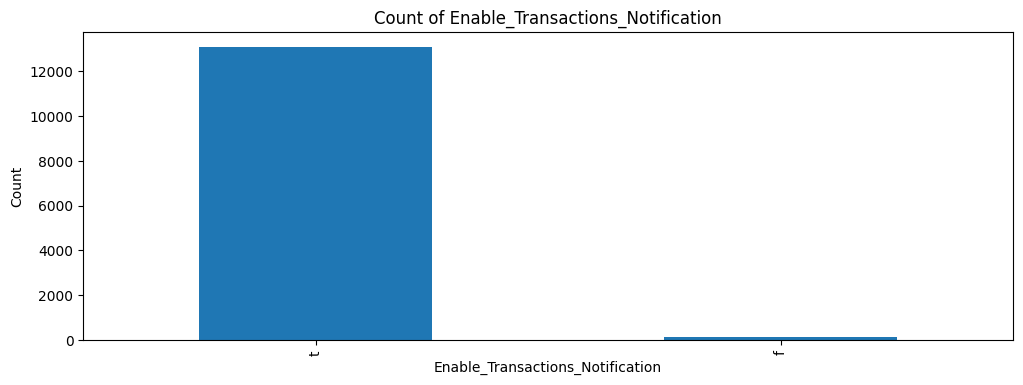

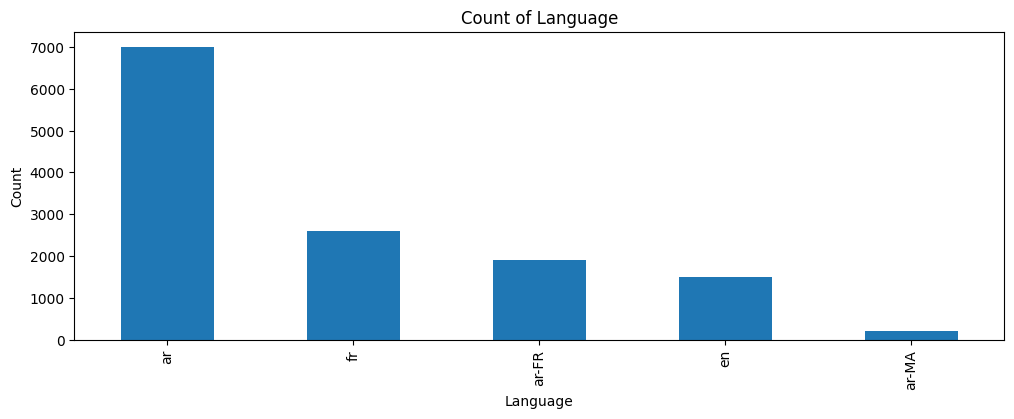

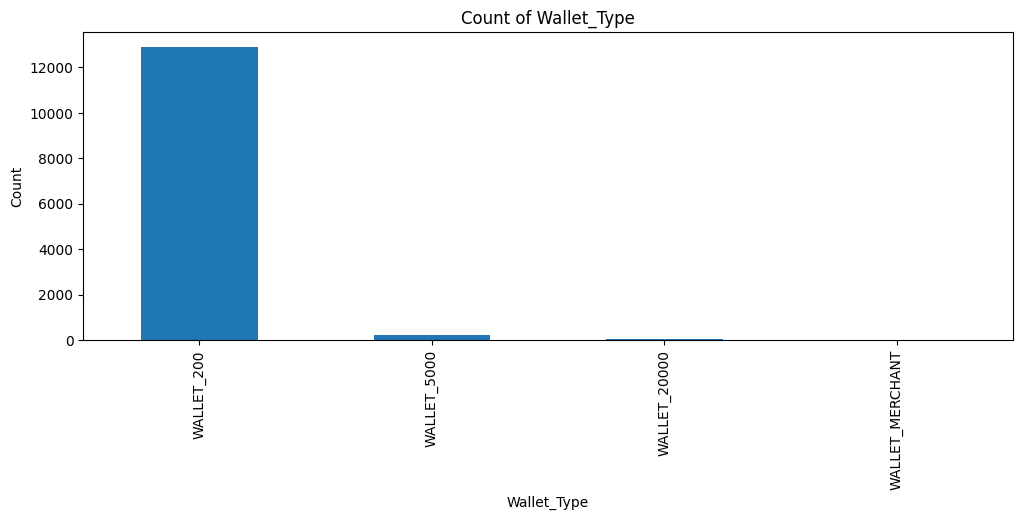

Text(0, 0.5, 'Count')

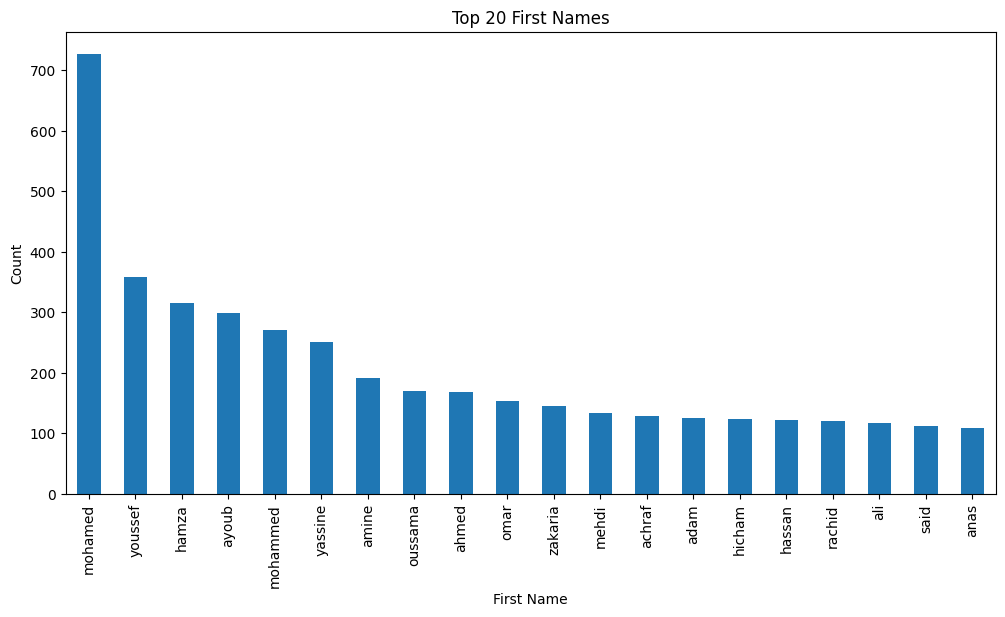

In [16]:
# Univariate analysis for numerical features in users_clean 
numerical_features = users_clean.select_dtypes(include=['int64', 'float64', 'datetime64[ns]']).columns
for feature in numerical_features:
    plt.figure(figsize=(12, 4))
    sns.histplot(users_clean[feature].dropna(), kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

# Univariate analysis for categorical features in users_clean
categorical_features = users_clean.select_dtypes(include=['object']).columns
categorical_features = categorical_features.drop(['User_Id','Avatar','First_Name'])  # Exclude 'User_Id', 'Avatar', and 'First_Name'
for feature in categorical_features:
    plt.figure(figsize=(12, 4))
    users_clean[feature].value_counts().plot(kind='bar')
    plt.title(f'Count of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.show()

# Visualizing the top 20 first names
top_20_names = users_clean['First_Name'].value_counts().head(20)
plt.figure(figsize=(12, 6))
top_20_names.plot(kind='bar')
plt.title('Top 20 First Names')
plt.xlabel('First Name')
plt.ylabel('Count')

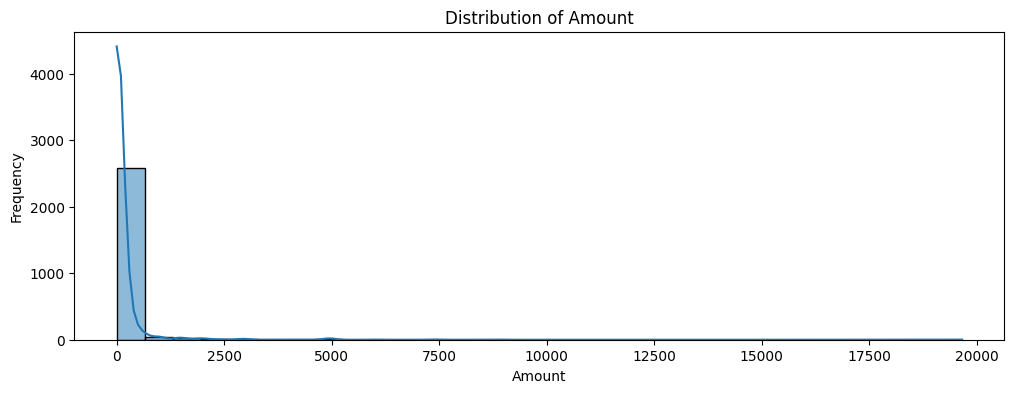

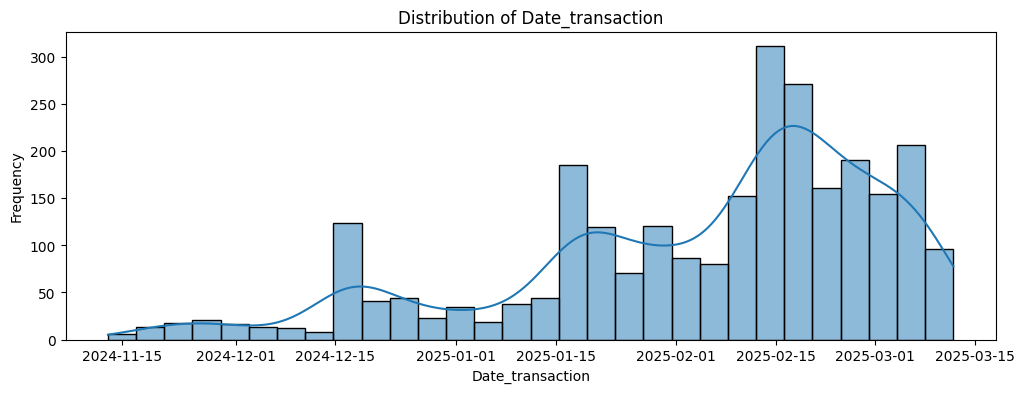

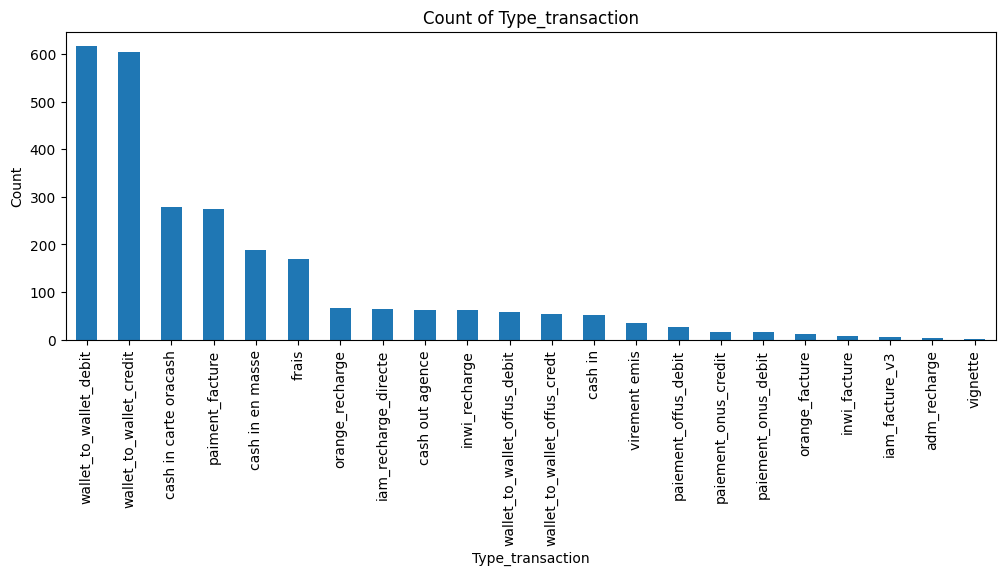

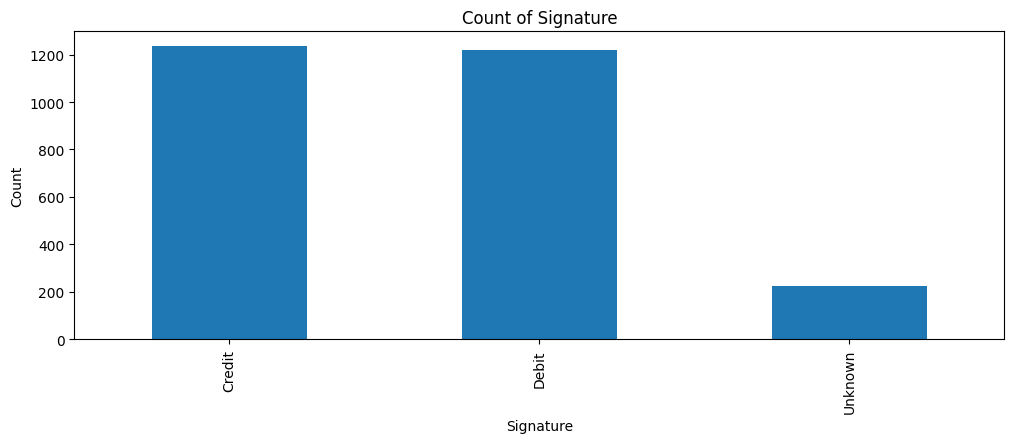

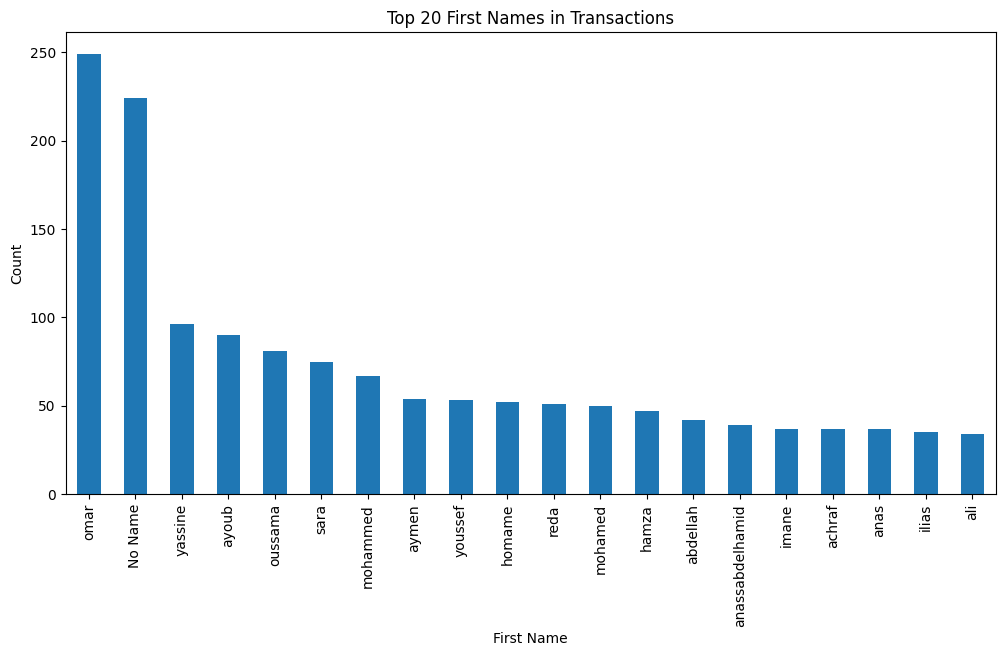

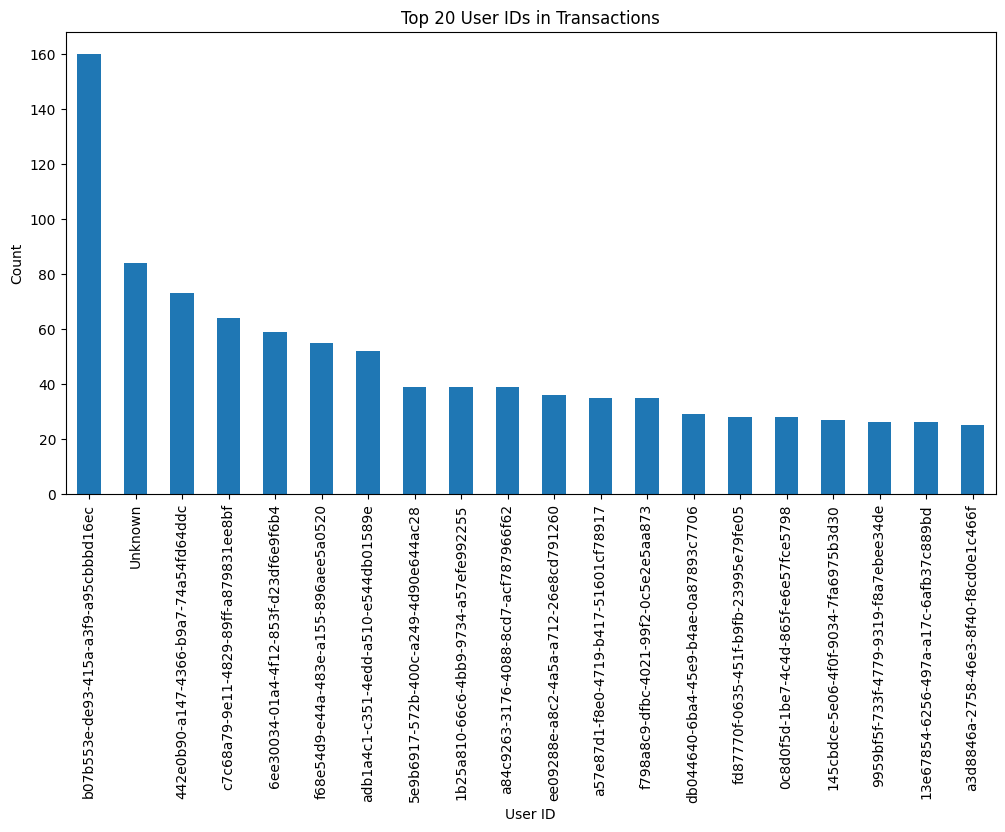

In [17]:
# Univariate analysis for numerical features in transactions
numerical_features = transactions_clean.select_dtypes(include=['int64', 'float64', 'datetime64[ns]']).columns
for feature in numerical_features:
    plt.figure(figsize=(12, 4))
    sns.histplot(transactions_clean[feature].dropna(), kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

# Univariate analysis for categorical features in transactions
categorical_features = transactions_clean.select_dtypes(include=['object']).columns
categorical_features = categorical_features.drop(['User_Id', 'First_Name', 'Time'])  # Exclude User_Id and First_Name
for feature in categorical_features:
    plt.figure(figsize=(12, 4))
    transactions_clean[feature].value_counts().plot(kind='bar')
    plt.title(f'Count of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    
    plt.show()

# Visualizing the top 20 first names
top_20_names = transactions_clean['First_Name'].value_counts().head(20)
plt.figure(figsize=(12, 6))
top_20_names.plot(kind='bar')
plt.title('Top 20 First Names in Transactions')
plt.xlabel('First Name')
plt.ylabel('Count')
plt.show()

# Visualizing the top 20 User IDs
top_20_ids = transactions_clean['User_Id'].value_counts().head(20)
plt.figure(figsize=(12, 6))
top_20_ids.plot(kind='bar')
plt.title('Top 20 User IDs in Transactions')
plt.xlabel('User ID')
plt.ylabel('Count')
plt.show()

## Feature Engineering :
Feature engineering is a critical step in the machine learning pipeline that involves transforming raw data into meaningful features to improve the performance of predictive models. In this project, new features are extracted from the `transactions` dataset, such as transaction counts, average transaction amounts, and activity periods, to merge this information with the `users` dataset. This integration enables a comprehensive view of user behavior and enhances the model's ability to predict churn. The process also includes encoding categorical variables, scaling numerical features, and creating new features through domain knowledge or mathematical transformations. By enhancing the quality and relevance of the input data, feature engineering helps to reduce noise, improve model interpretability, and optimize predictive accuracy.

In [18]:
import pandas as pd

LARGE_TIME_VALUE = 999999.0  # Used to mark "undefined" transaction timing gaps (e.g. 1 or 0 txn)

# --- 1. Time Preprocessing ---
transactions_clean['Time'] = pd.to_timedelta(transactions_clean['Time'].astype(str))
transactions_clean['Transaction_Datetime'] = transactions_clean['Date_transaction'] + transactions_clean['Time']

# Sort transactions to compute diffs later
transactions_clean = transactions_clean.sort_values(by=['User_Id', 'Transaction_Datetime'])

# --- 2. Aggregate General Transaction Stats ---
transaction_features = transactions_clean.groupby('User_Id').agg(
    num_transactions=('Amount', 'count'),
    avg_transaction_amount=('Amount', 'mean'),
    max_transaction_amount=('Amount', 'max'),
    min_transaction_amount=('Amount', 'min'),
    total_transaction_amount=('Amount', 'sum'),
    last_transaction_date=('Transaction_Datetime', 'max'),
    first_transaction_date=('Transaction_Datetime', 'min')
).reset_index()

# Compute transaction activity period
transaction_features['transaction_activity_period'] = (
    transaction_features['last_transaction_date'] - transaction_features['first_transaction_date']
).dt.days

# Drop raw date columns
transaction_features.drop(columns=['last_transaction_date', 'first_transaction_date'], inplace=True)

# --- 3. Transaction Type Counts ---
# Debit/Credit counts
debit_count = transactions_clean[transactions_clean['Signature'] == 'Debit'].groupby('User_Id').size().rename('num_debit_transactions')
credit_count = transactions_clean[transactions_clean['Signature'] == 'Credit'].groupby('User_Id').size().rename('num_credit_transactions')

# Transaction type counts (unstack makes columns for each type)
txn_type_counts = transactions_clean.groupby(['User_Id', 'Type_transaction']).size().unstack(fill_value=0)

# Merge all into transaction_features
transaction_features = transaction_features.merge(debit_count, on='User_Id', how='left')
transaction_features = transaction_features.merge(credit_count, on='User_Id', how='left')
transaction_features = transaction_features.merge(txn_type_counts, on='User_Id', how='left')

transaction_features.fillna(0, inplace=True)  # Ensure all missing features are 0

# --- 4. Merge to User Table ---
users_clean = users_clean.merge(transaction_features, on='User_Id', how='left')

# --- 5. Churn and Time Features ---
users_clean['churn_target'] = users_clean['Deleted_At'].notna().astype(int)

users_clean['time_since_creation'] = (pd.Timestamp.now() - users_clean['Created_At']).dt.days
users_clean['activity_duration'] = (users_clean['Last_Online'] - users_clean['Created_At']).dt.days
users_clean['time_since_last_update'] = (pd.Timestamp.now() - users_clean['Updated_At']).dt.days

# --- 6. Time Between Transactions ---
transactions_clean['transaction_diff'] = transactions_clean.groupby('User_Id')['Transaction_Datetime'].diff().dt.total_seconds() / 3600

txn_diffs = transactions_clean.groupby('User_Id')['transaction_diff'].agg([
    ('min_time_between_txn_hours', 'min'),
    ('max_time_between_txn_hours', 'max'),
    ('avg_time_between_txn_hours', 'mean')
]).reset_index()

txn_diffs.fillna(LARGE_TIME_VALUE, inplace=True)  # For users with 1 or 0 transactions
users_clean = users_clean.merge(txn_diffs, on='User_Id', how='left')

# --- 7. Frequency-Based Features ---
users_clean['txn_per_active_day'] = users_clean.apply(
    lambda row: row['num_transactions'] / row['activity_duration']
    if row['activity_duration'] > 0 else 0,
    axis=1
)

# --- 8. Aggregate Credit/Debit Amounts ---
debit_sum = transactions_clean[transactions_clean['Signature'] == 'Debit'].groupby('User_Id')['Amount'].sum().rename('total_debit_amount')
credit_sum = transactions_clean[transactions_clean['Signature'] == 'Credit'].groupby('User_Id')['Amount'].sum().rename('total_credit_amount')

users_clean = users_clean.merge(debit_sum, on='User_Id', how='left')
users_clean = users_clean.merge(credit_sum, on='User_Id', how='left')
users_clean['total_debit_amount'] = users_clean['total_debit_amount'].fillna(0)
users_clean['total_credit_amount'] = users_clean['total_credit_amount'].fillna(0)

# --- 9. Derived Metrics ---
users_clean['net_money_flow'] = users_clean['total_credit_amount'] - users_clean['total_debit_amount']
users_clean['txn_amount_x_freq'] = users_clean['avg_transaction_amount'] * users_clean['txn_per_active_day']
users_clean['activity_x_total_amount'] = users_clean['activity_duration'] * users_clean['total_transaction_amount']
users_clean['is_profitable'] = (users_clean['total_credit_amount'] > users_clean['total_debit_amount']).astype(int)

# Time from creation to now as a lifespan
users_clean['account_duration'] = (pd.Timestamp.now() - users_clean['Created_At']).dt.days
users_clean['account_lifespan_x_net_flow'] = users_clean['account_duration'] * users_clean['net_money_flow']

# --- 10. First & Last Transaction Dates ---
txn_dates = transactions_clean.groupby('User_Id')['Transaction_Datetime'].agg(['min', 'max']).reset_index()
txn_dates.columns = ['User_Id', 'first_txn_date', 'last_txn_date']

users_clean = users_clean.merge(txn_dates, on='User_Id', how='left')
users_clean['first_txn_date'] = users_clean['first_txn_date'].fillna(users_clean['Created_At'])
users_clean['last_txn_date'] = users_clean['last_txn_date'].fillna(users_clean['Created_At'])

# --- 11. Dormancy & Engagement ---
users_clean['post_txn_dormancy'] = (users_clean['Last_Online'] - users_clean['last_txn_date']).dt.days
users_clean['pre_txn_engagement'] = (users_clean['first_txn_date'] - users_clean['Created_At']).dt.days

# --- 12. Time Before Churn (only for churned) ---
users_clean['updated_before_churn'] = users_clean.apply(
    lambda row: (row['Deleted_At'] - row['Updated_At']).days if row['churn_target'] == 1 else 0,
    axis=1
)

# --- 13. Days Since Seen Online ---
users_clean['days_online_until_now'] = users_clean.apply(
    lambda row: (pd.Timestamp.now() - row['Last_Online']).days if pd.notna(row['Last_Online']) else -1,
    axis=1
)
users_clean['days_since_seen'] = (pd.Timestamp.now() - users_clean['Last_Online']).dt.days

# --- 14. Final NA Cleanup ---
users_clean.fillna({
    'min_time_between_txn_hours': LARGE_TIME_VALUE,
    'max_time_between_txn_hours': LARGE_TIME_VALUE,
    'avg_time_between_txn_hours': LARGE_TIME_VALUE,
    'txn_per_active_day': 0,
    'txn_amount_x_freq': 0,
    'activity_x_total_amount': 0,
    'net_money_flow': 0,
    'updated_before_churn': 0,
    'days_online_before_churn': 0
}, inplace=True)

# Fill remaining transaction feature NaNs (users with no transactions)
users_clean.fillna({col: 0 for col in transaction_features.columns if col != 'User_Id'}, inplace=True)


In [19]:
print(users_clean.columns)

Index(['User_Id', 'User_Type', 'Gender', 'Created_At', 'Updated_At',
       'Deleted_At', 'First_Name', 'Last_Online', 'Avatar',
       'Must_Pay_Monthly_Fee', 'Enable_Messages_Notification',
       'Enable_Transactions_Notification', 'Language', 'Wallet_Type',
       'num_transactions', 'avg_transaction_amount', 'max_transaction_amount',
       'min_transaction_amount', 'total_transaction_amount',
       'transaction_activity_period', 'num_debit_transactions',
       'num_credit_transactions', 'adm_recharge', 'cash in',
       'cash in carte oracash', 'cash in en masse', 'cash out agence', 'frais',
       'iam_facture_v3', 'iam_recharge_directe', 'inwi_facture',
       'inwi_recharge', 'orange_facture', 'orange_recharge',
       'paiement_offus_debit', 'paiement_onus_credit', 'paiement_onus_debit',
       'paiment_facture', 'vignette', 'virement emis',
       'wallet_to_wallet_credit', 'wallet_to_wallet_debit',
       'wallet_to_wallet_offus_credt', 'wallet_to_wallet_offus_debit',
   

<Axes: >

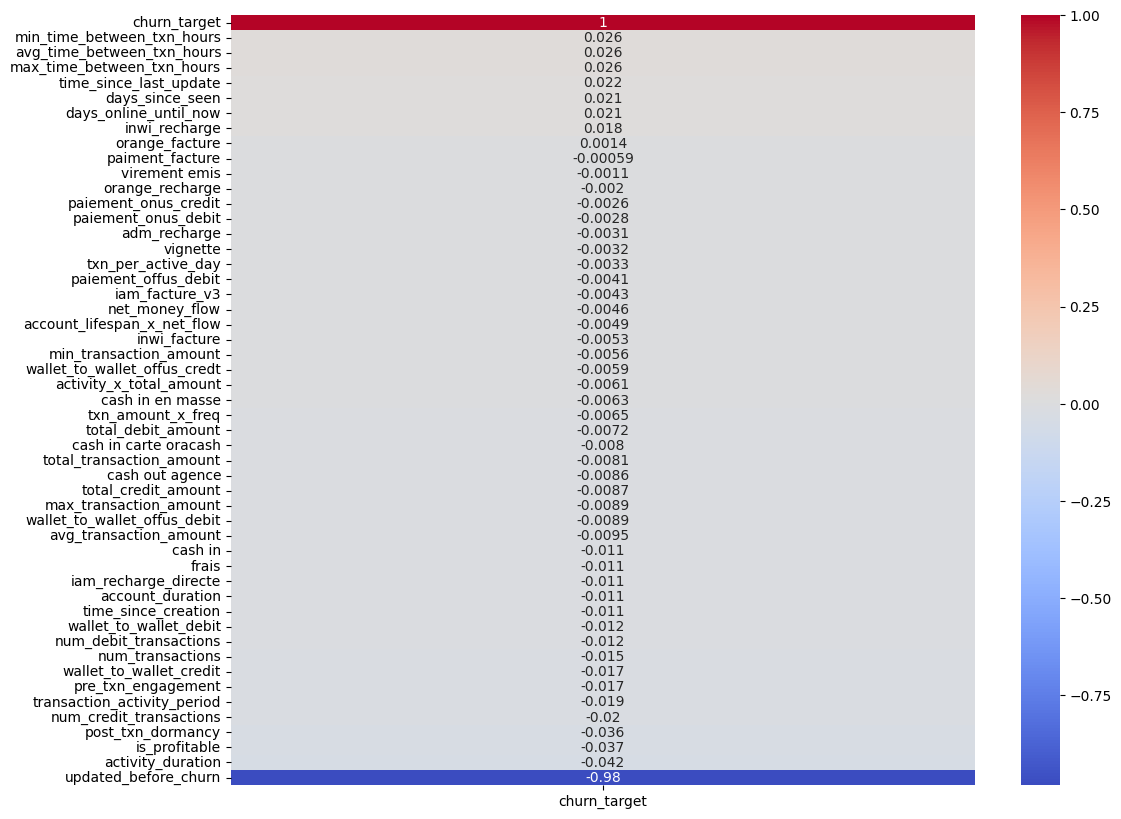

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))
sns.heatmap(users_clean.corr(numeric_only=True)[['churn_target']].sort_values(by='churn_target', ascending=False), annot=True, cmap='coolwarm')


In [21]:
print(users_clean.columns)

Index(['User_Id', 'User_Type', 'Gender', 'Created_At', 'Updated_At',
       'Deleted_At', 'First_Name', 'Last_Online', 'Avatar',
       'Must_Pay_Monthly_Fee', 'Enable_Messages_Notification',
       'Enable_Transactions_Notification', 'Language', 'Wallet_Type',
       'num_transactions', 'avg_transaction_amount', 'max_transaction_amount',
       'min_transaction_amount', 'total_transaction_amount',
       'transaction_activity_period', 'num_debit_transactions',
       'num_credit_transactions', 'adm_recharge', 'cash in',
       'cash in carte oracash', 'cash in en masse', 'cash out agence', 'frais',
       'iam_facture_v3', 'iam_recharge_directe', 'inwi_facture',
       'inwi_recharge', 'orange_facture', 'orange_recharge',
       'paiement_offus_debit', 'paiement_onus_credit', 'paiement_onus_debit',
       'paiment_facture', 'vignette', 'virement emis',
       'wallet_to_wallet_credit', 'wallet_to_wallet_debit',
       'wallet_to_wallet_offus_credt', 'wallet_to_wallet_offus_debit',
   

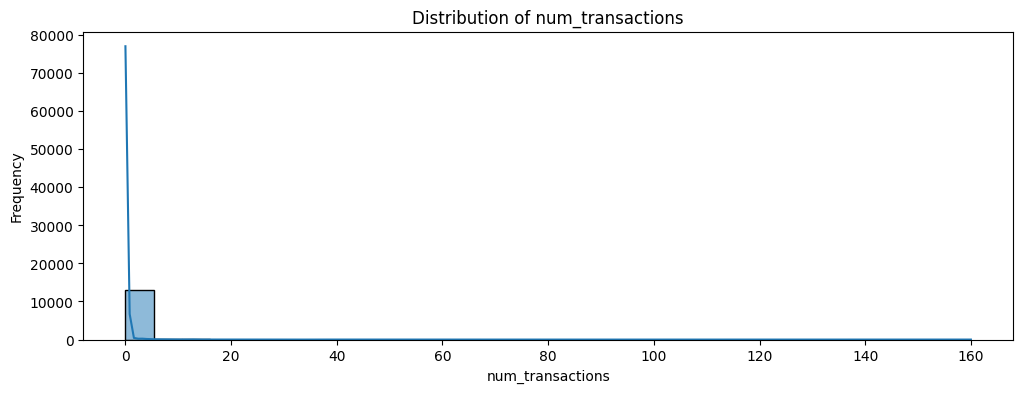

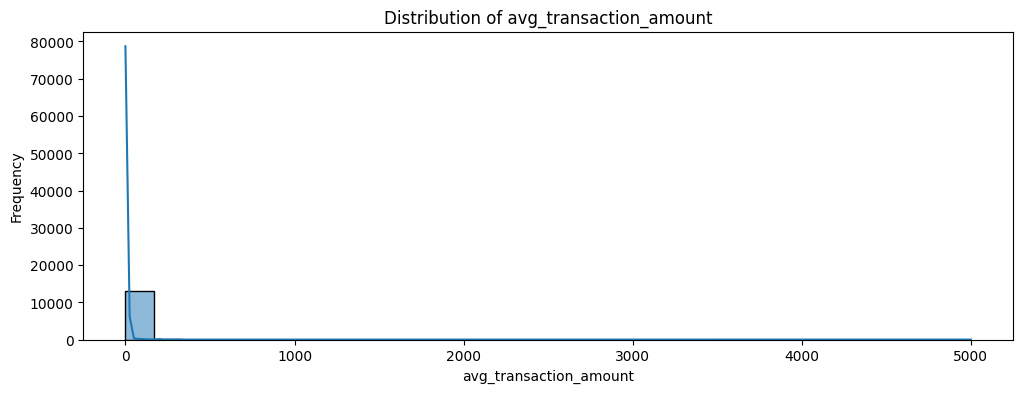

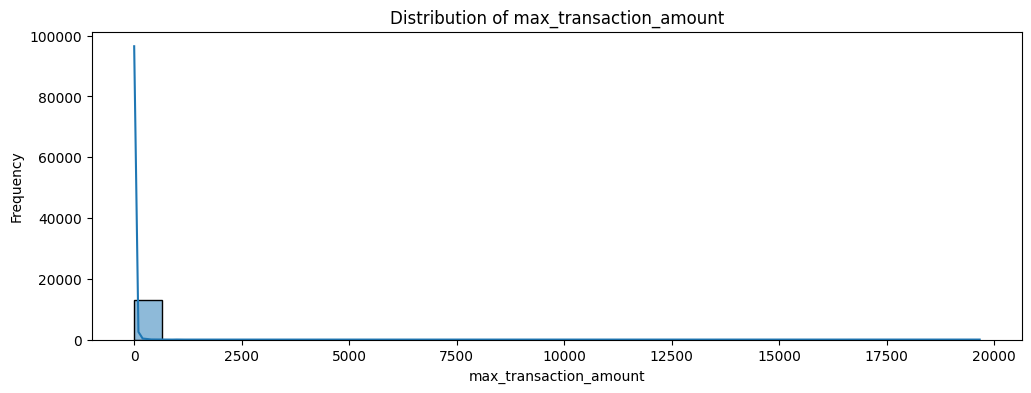

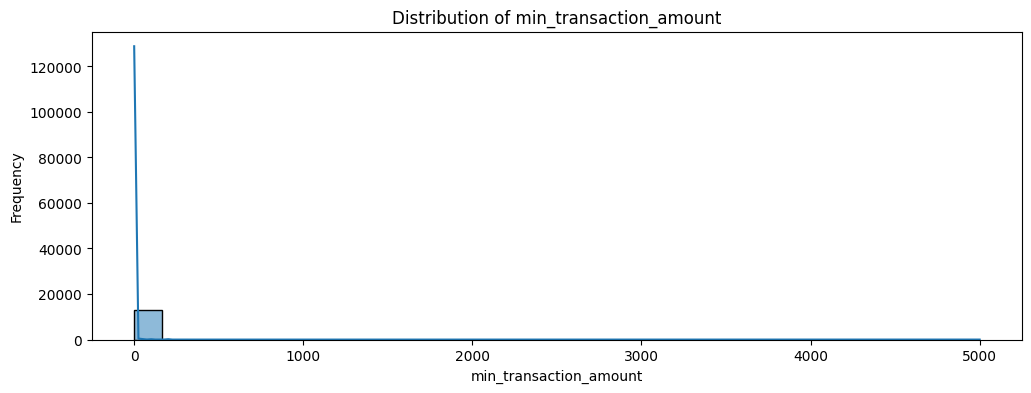

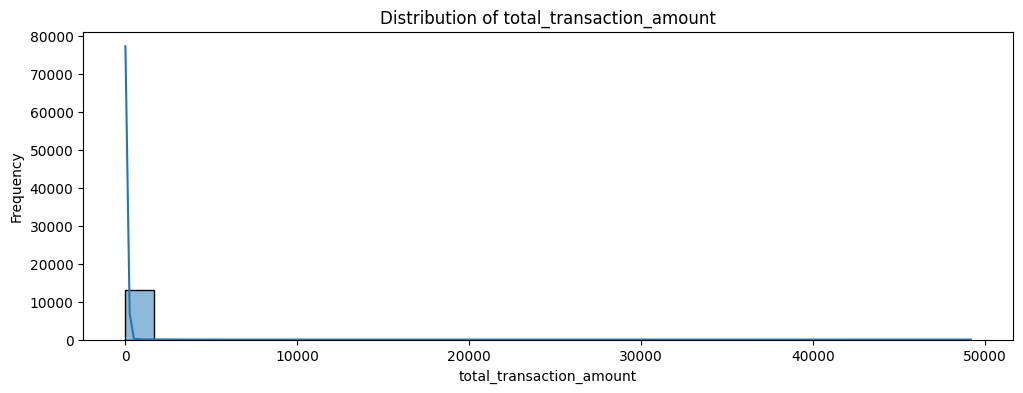

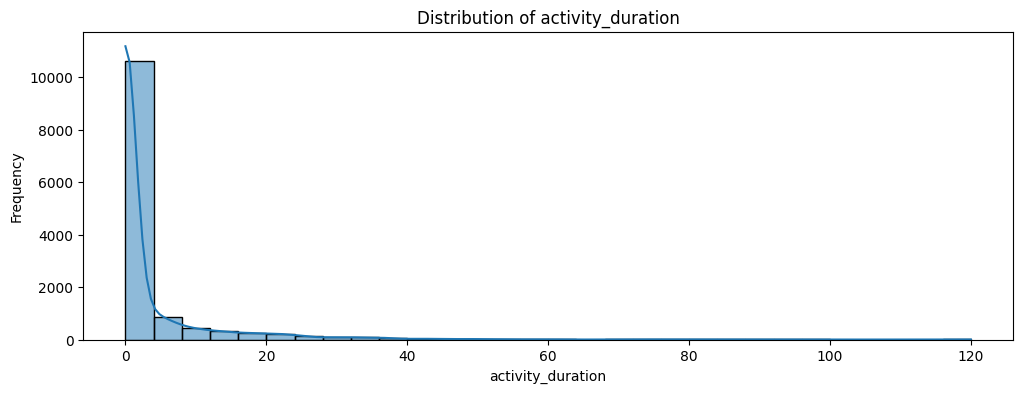

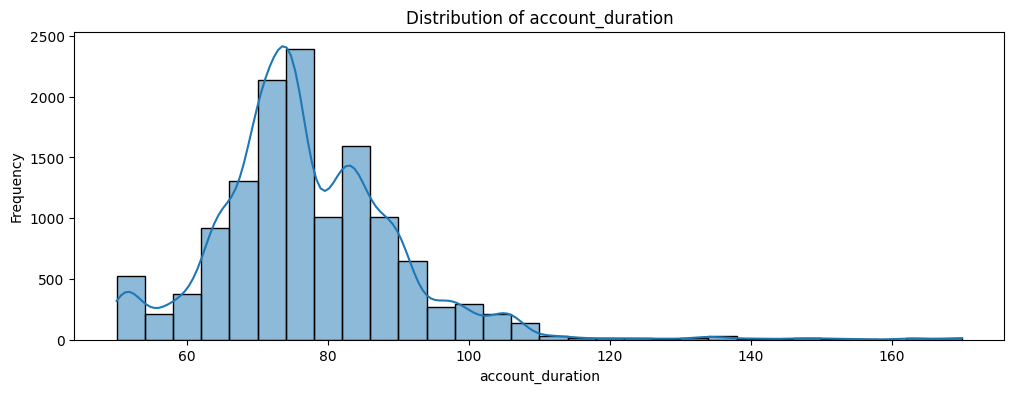

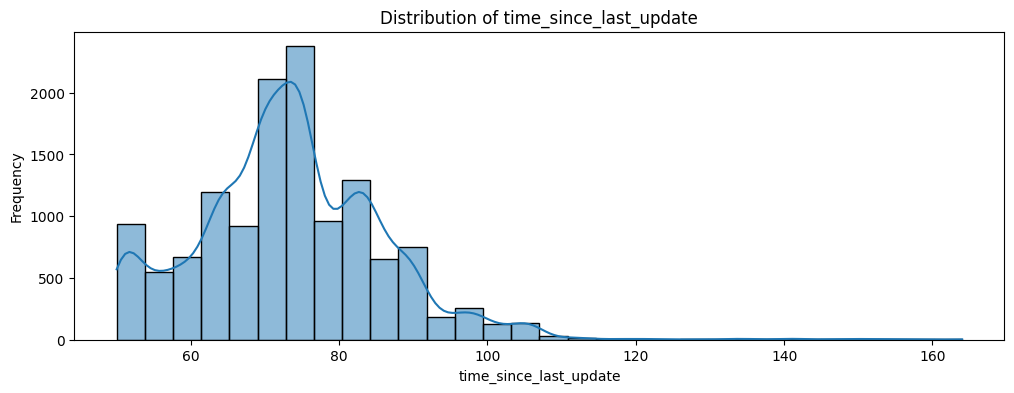

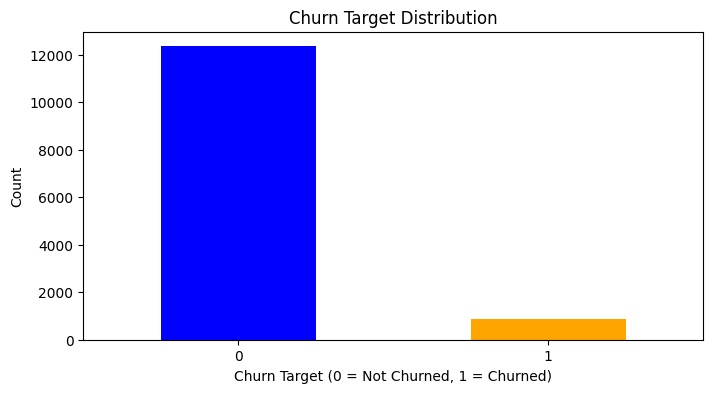

In [22]:
# Visualizing new numerical features
new_numerical_features = ['num_transactions', 'avg_transaction_amount', 'max_transaction_amount', 
                          'min_transaction_amount', 'total_transaction_amount', 'activity_duration', 'account_duration', 'time_since_last_update']

for feature in new_numerical_features:
    plt.figure(figsize=(12, 4))
    sns.histplot(users_clean[feature], kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

# Visualizing the churn target
plt.figure(figsize=(8, 4))
users_clean['churn_target'].value_counts().plot(kind='bar', color=['blue', 'orange'])
plt.title('Churn Target Distribution')
plt.xlabel('Churn Target (0 = Not Churned, 1 = Churned)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

In [23]:
# Extracting classes from Avatar links
users_clean['Avatar_Class'] = users_clean['Avatar'].apply(lambda x: 'common' if 'common' in x else 'users' if 'users' in x else 'unknown')

# Drop the Avatar column as it is no longer needed
users_clean.drop(columns=['Avatar'], inplace=True)

In [24]:
# Identify categorical columns in users_clean
categorical_columns = users_clean.select_dtypes(include=['object']).columns

# Exclude 'First_Name', 'User_Id'from encoding
categorical_columns = categorical_columns.drop(['First_Name', 'User_Id'])

# Replace 't' with 1 and 'f' with 0 for columns with only two unique values
binary_columns = [col for col in categorical_columns if users_clean[col].nunique() == 2]
for col in binary_columns:
    users_clean[col] = users_clean[col].replace({'t': 1, 'f': 0})

# Remove binary columns from the list of columns to encode
categorical_columns = categorical_columns.drop(binary_columns)
print(categorical_columns)
# Perform one-hot encoding for the remaining categorical columns
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoded_data = encoder.fit_transform(users_clean[categorical_columns])

# Create a DataFrame for the encoded columns
encoded_columns = encoder.get_feature_names_out(categorical_columns)
encoded_df = pd.DataFrame(encoded_data, columns=encoded_columns, index=users_clean.index)

# Concatenate the encoded columns with the original DataFrame
users_clean_encoded = pd.concat([users_clean.drop(categorical_columns, axis=1), encoded_df], axis=1)

users_clean_encoded.head()

C:\Users\USER\AppData\Local\Temp\ipykernel_16336\2899067392.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  users_clean[col] = users_clean[col].replace({'t': 1, 'f': 0})


Index(['Gender', 'Language', 'Wallet_Type', 'Avatar_Class'], dtype='object')


,User_Id,User_Type,Created_At,Updated_At,Deleted_At,First_Name,Last_Online,Must_Pay_Monthly_Fee,Enable_Messages_Notification,Enable_Transactions_Notification,...,Language_ar-MA,Language_en,Language_fr,Wallet_Type_WALLET_200,Wallet_Type_WALLET_20000,Wallet_Type_WALLET_5000,Wallet_Type_WALLET_MERCHANT,Avatar_Class_common,Avatar_Class_unknown,Avatar_Class_users
0,d08cfe7e-a2ed-4fdf-8ebb-f2104b1bf657,CUSTOMER,2025-01-25 22:20:53.566,2025-01-25 22:24:54.162,NaT,el mustapha,2025-01-25 22:24:54.141,0,1,1,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,f5a9d798-00e0-4c6c-ae41-56e8c2b29b47,CUSTOMER,2025-03-02 04:14:34.529,2025-03-02 04:17:13.600,NaT,taoufik,2025-03-02 04:17:13.576,0,1,1,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,27ee6b57-8043-4aae-9fdf-9e07b2862b34,CUSTOMER,2025-01-22 07:11:10.252,2025-01-26 22:57:49.909,NaT,bilal,2025-01-26 22:57:49.873,0,1,1,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,cf72657e-4a71-4a05-9dfb-ac15d95fbfa9,CUSTOMER,2024-11-19 14:33:57.428,2024-11-19 14:58:56.101,NaT,amina,2024-11-19 14:58:56.074,0,1,1,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,458d9f2b-c65c-4ec5-8c50-02f1ddf7eb15,CUSTOMER,2025-01-18 21:23:50.171,2025-01-19 14:38:28.732,NaT,walid,2025-01-19 14:38:28.708,0,1,1,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [25]:
# Drop non-numerical and unnecessary features except for User_Id
columns_to_keep = ['User_Id'] + users_clean_encoded.select_dtypes(include=['number']).columns.tolist()
users_clean_encoded = users_clean_encoded[columns_to_keep]

users_clean_encoded.head()

,User_Id,Must_Pay_Monthly_Fee,Enable_Messages_Notification,Enable_Transactions_Notification,num_transactions,avg_transaction_amount,max_transaction_amount,min_transaction_amount,total_transaction_amount,transaction_activity_period,...,Language_ar-MA,Language_en,Language_fr,Wallet_Type_WALLET_200,Wallet_Type_WALLET_20000,Wallet_Type_WALLET_5000,Wallet_Type_WALLET_MERCHANT,Avatar_Class_common,Avatar_Class_unknown,Avatar_Class_users
0,d08cfe7e-a2ed-4fdf-8ebb-f2104b1bf657,0,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,f5a9d798-00e0-4c6c-ae41-56e8c2b29b47,0,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,27ee6b57-8043-4aae-9fdf-9e07b2862b34,0,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,cf72657e-4a71-4a05-9dfb-ac15d95fbfa9,0,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,458d9f2b-c65c-4ec5-8c50-02f1ddf7eb15,0,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [26]:
pd.set_option('display.max_columns', None)
users_clean_encoded.columns

Index(['User_Id', 'Must_Pay_Monthly_Fee', 'Enable_Messages_Notification',
       'Enable_Transactions_Notification', 'num_transactions',
       'avg_transaction_amount', 'max_transaction_amount',
       'min_transaction_amount', 'total_transaction_amount',
       'transaction_activity_period', 'num_debit_transactions',
       'num_credit_transactions', 'adm_recharge', 'cash in',
       'cash in carte oracash', 'cash in en masse', 'cash out agence', 'frais',
       'iam_facture_v3', 'iam_recharge_directe', 'inwi_facture',
       'inwi_recharge', 'orange_facture', 'orange_recharge',
       'paiement_offus_debit', 'paiement_onus_credit', 'paiement_onus_debit',
       'paiment_facture', 'vignette', 'virement emis',
       'wallet_to_wallet_credit', 'wallet_to_wallet_debit',
       'wallet_to_wallet_offus_credt', 'wallet_to_wallet_offus_debit',
       'churn_target', 'time_since_creation', 'activity_duration',
       'time_since_last_update', 'min_time_between_txn_hours',
       'max_time_b

In [27]:
users_clean_encoded.iloc[:,0:30].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13203 entries, 0 to 13202
Data columns (total 30 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   User_Id                           13203 non-null  object 
 1   Must_Pay_Monthly_Fee              13203 non-null  int64  
 2   Enable_Messages_Notification      13203 non-null  int64  
 3   Enable_Transactions_Notification  13203 non-null  int64  
 4   num_transactions                  13203 non-null  float64
 5   avg_transaction_amount            13203 non-null  float64
 6   max_transaction_amount            13203 non-null  float64
 7   min_transaction_amount            13203 non-null  float64
 8   total_transaction_amount          13203 non-null  float64
 9   transaction_activity_period       13203 non-null  float64
 10  num_debit_transactions            13203 non-null  float64
 11  num_credit_transactions           13203 non-null  float64
 12  adm_

In [28]:
data = users_clean_encoded.copy()

## Data Imbalance Check:
Churn prediction problems often involve imbalanced datasets because the number of users who churn (e.g., delete their accounts) is typically much smaller than the number of users who remain active. This imbalance can lead to challenges in training machine learning models, as standard algorithms may become biased toward the majority class (non-churners), resulting in poor performance for the minority class (churners). To address this, it is essential to use specialized techniques such as oversampling the minority class, undersampling the majority class, or applying class weights to balance the model's focus. Additionally, traditional metrics like accuracy may not be suitable for evaluating imbalanced datasets, as they can be misleading. Instead, metrics such as precision, recall, F1-score, and area under the ROC curve (AUC-ROC) are more appropriate, as they provide a better understanding of the model's performance in identifying churners.

Text(0, 0.5, 'Count')

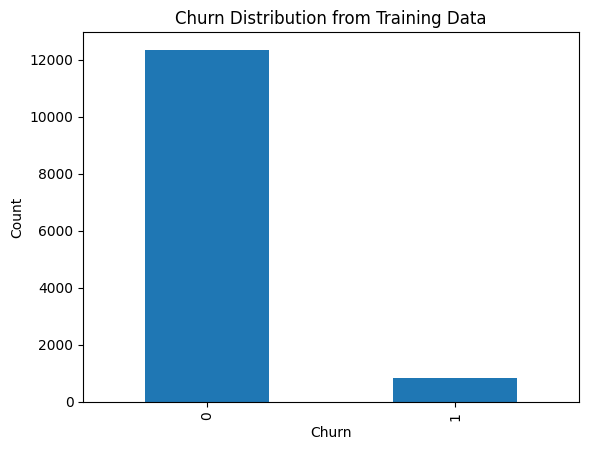

In [29]:
# visualizing the churn target distribution
data['churn_target'].value_counts().plot(kind='bar')
plt.title('Churn Distribution from Training Data')
plt.xlabel('Churn')
plt.ylabel('Count')

## Multivariate analysis:

In [31]:
# Calculate correlations with the target variable, excluding User_Id
correlations = data.drop(columns=['User_Id']).corr()['churn_target'].apply(lambda x : abs(x)).sort_values(ascending=False)

# Display the correlations
print(correlations)

churn_target                        1.000000
updated_before_churn                0.981722
Language_ar                         0.066459
Enable_Transactions_Notification    0.044134
activity_duration                   0.042158
                                      ...   
paiement_onus_credit                0.002589
orange_recharge                     0.001980
orange_facture                      0.001358
virement emis                       0.001064
paiment_facture                     0.000586
Name: churn_target, Length: 69, dtype: float64


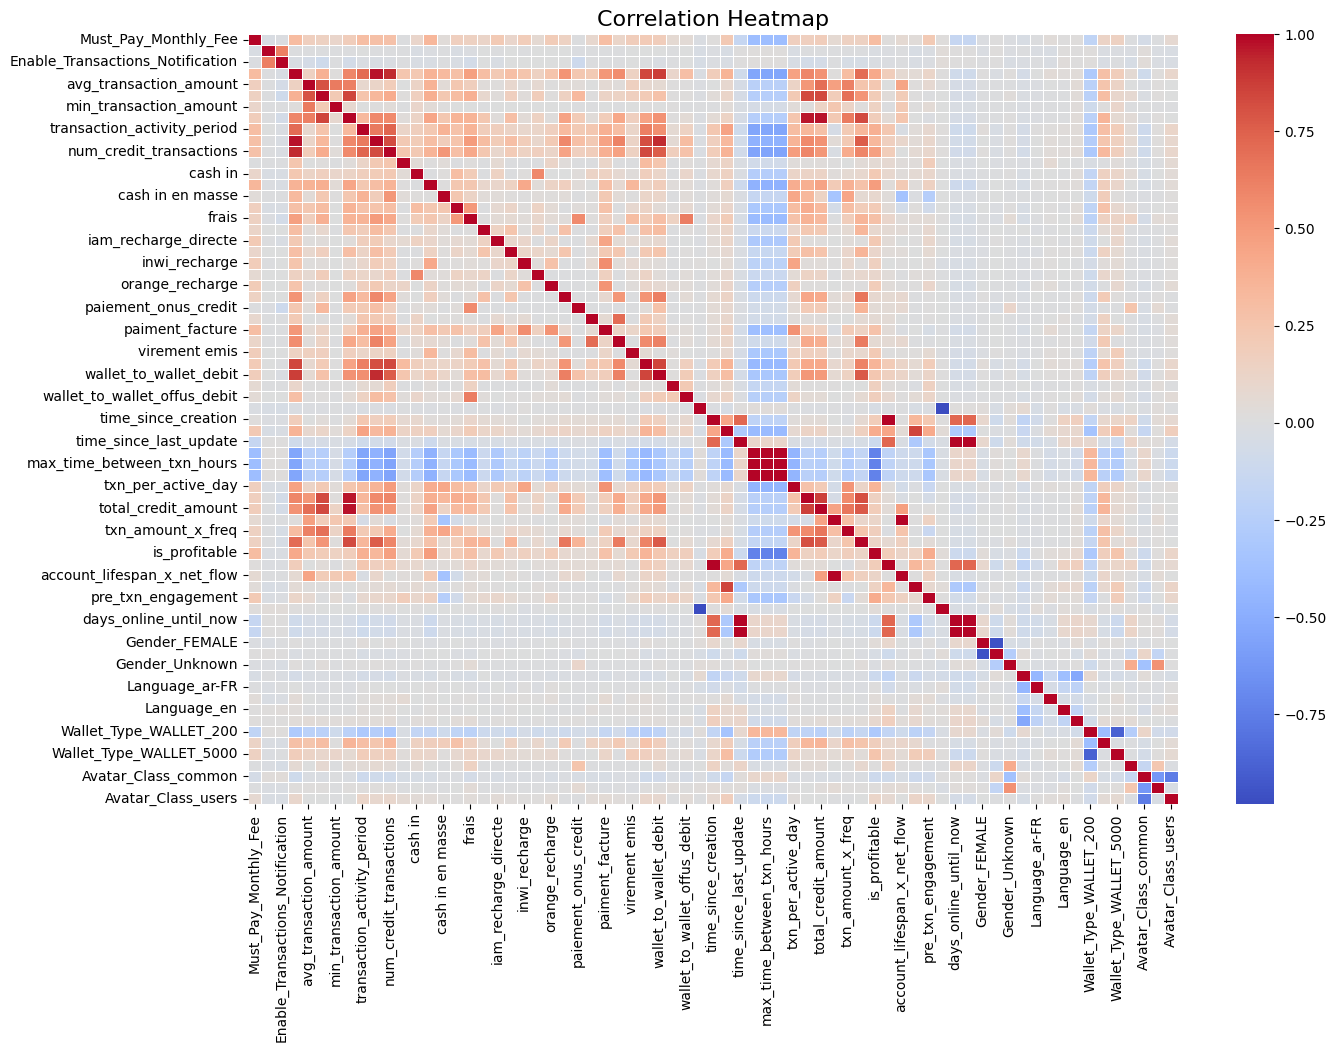

In [32]:
import seaborn as sns

import matplotlib.pyplot as plt

# Compute the correlation matrix
correlation_matrix = data.drop(columns= ["User_Id"]).corr()

# Set up the matplotlib figure
plt.figure(figsize=(15, 10))

# Draw the heatmap
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', fmt='.2f', linewidths=0.5)

# Add title
plt.title('Correlation Heatmap', fontsize=16)

# Show the plot
plt.show()

### Correlation Matrix Results

The correlation matrix provides insights into the relationships between numerical features in the dataset. Each cell in the matrix represents the correlation coefficient between two variables, ranging from -1 to 1:

- **Positive Correlation (close to 1):** Indicates that as one variable increases, the other tends to increase as well.
- **Negative Correlation (close to -1):** Indicates that as one variable increases, the other tends to decrease.
- **No Correlation (close to 0):** Indicates no linear relationship between the variables.

#### Key Observations:
1. **Churn Target Correlations:**
    - Features like `account_duration`, `activity_duration`, and `time_since_last_update` may show significant correlations with `churn_target`. For example:
      - A **positive correlation** with `time_since_last_update` might indicate that users who haven't updated their accounts recently are more likely to churn.
      - A **negative correlation** with `activity_duration` might suggest that users with longer activity durations are less likely to churn.

2. **Transaction Features:**
    - Features such as `num_transactions`, `total_transaction_amount`, and `transaction_activity_period` may have correlations with each other, as they all relate to user transaction behavior.
    - A **positive correlation** between `num_transactions` and `total_transaction_amount` is expected, as more transactions typically result in higher total amounts.

3. **Wallet and Notification Features:**
    - Features like `Enable_Transactions_Notification` and `Enable_Messages_Notification` might show weak or no correlation with `churn_target`, indicating that enabling notifications alone may not strongly influence churn.

4. **Multicollinearity:**
    - Some features, such as `avg_transaction_amount`, `max_transaction_amount`, and `min_transaction_amount`, may exhibit high correlations with `total_transaction_amount`, indicating potential multicollinearity. This could affect model performance and may require dimensionality reduction techniques like PCA or feature selection.

5. **Gender and Language Features:**
    - Encoded categorical features like `Gender_MALE` and `Language_en` may show weak correlations with `churn_target`, as demographic factors might have limited influence on churn.

In [33]:
data = data.drop(columns=['max_transaction_amount', 'min_transaction_amount', 'total_transaction_amount'])

In [34]:
data = data.drop(columns=['updated_before_churn'])

In [35]:
data.shape

(13203, 66)

In [37]:
data.columns

Index(['User_Id', 'Must_Pay_Monthly_Fee', 'Enable_Messages_Notification',
       'Enable_Transactions_Notification', 'num_transactions',
       'avg_transaction_amount', 'transaction_activity_period',
       'num_debit_transactions', 'num_credit_transactions', 'adm_recharge',
       'cash in', 'cash in carte oracash', 'cash in en masse',
       'cash out agence', 'frais', 'iam_facture_v3', 'iam_recharge_directe',
       'inwi_facture', 'inwi_recharge', 'orange_facture', 'orange_recharge',
       'paiement_offus_debit', 'paiement_onus_credit', 'paiement_onus_debit',
       'paiment_facture', 'vignette', 'virement emis',
       'wallet_to_wallet_credit', 'wallet_to_wallet_debit',
       'wallet_to_wallet_offus_credt', 'wallet_to_wallet_offus_debit',
       'churn_target', 'time_since_creation', 'activity_duration',
       'time_since_last_update', 'min_time_between_txn_hours',
       'max_time_between_txn_hours', 'avg_time_between_txn_hours',
       'txn_per_active_day', 'total_debit_amo

In [38]:
data.head()

,User_Id,Must_Pay_Monthly_Fee,Enable_Messages_Notification,Enable_Transactions_Notification,num_transactions,avg_transaction_amount,transaction_activity_period,num_debit_transactions,num_credit_transactions,adm_recharge,cash in,cash in carte oracash,cash in en masse,cash out agence,frais,iam_facture_v3,iam_recharge_directe,inwi_facture,inwi_recharge,orange_facture,orange_recharge,paiement_offus_debit,paiement_onus_credit,paiement_onus_debit,paiment_facture,vignette,virement emis,wallet_to_wallet_credit,wallet_to_wallet_debit,wallet_to_wallet_offus_credt,wallet_to_wallet_offus_debit,churn_target,time_since_creation,activity_duration,time_since_last_update,min_time_between_txn_hours,max_time_between_txn_hours,avg_time_between_txn_hours,txn_per_active_day,total_debit_amount,total_credit_amount,net_money_flow,txn_amount_x_freq,activity_x_total_amount,is_profitable,account_duration,account_lifespan_x_net_flow,post_txn_dormancy,pre_txn_engagement,days_online_until_now,days_since_seen,Gender_FEMALE,Gender_MALE,Gender_Unknown,Language_ar,Language_ar-FR,Language_ar-MA,Language_en,Language_fr,Wallet_Type_WALLET_200,Wallet_Type_WALLET_20000,Wallet_Type_WALLET_5000,Wallet_Type_WALLET_MERCHANT,Avatar_Class_common,Avatar_Class_unknown,Avatar_Class_users
0,d08cfe7e-a2ed-4fdf-8ebb-f2104b1bf657,0,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,96,0,96,999999.0,999999.0,999999.0,0.0,0.0,0.0,0.0,0.0,0.0,0,96,0.0,0,0,96,96,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,f5a9d798-00e0-4c6c-ae41-56e8c2b29b47,0,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,61,0,61,999999.0,999999.0,999999.0,0.0,0.0,0.0,0.0,0.0,0.0,0,61,0.0,0,0,61,61,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,27ee6b57-8043-4aae-9fdf-9e07b2862b34,0,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,100,4,95,999999.0,999999.0,999999.0,0.0,0.0,0.0,0.0,0.0,0.0,0,100,0.0,4,0,95,95,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,cf72657e-4a71-4a05-9dfb-ac15d95fbfa9,0,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,164,0,164,999999.0,999999.0,999999.0,0.0,0.0,0.0,0.0,0.0,0.0,0,164,0.0,0,0,164,164,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,458d9f2b-c65c-4ec5-8c50-02f1ddf7eb15,0,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,103,0,103,999999.0,999999.0,999999.0,0.0,0.0,0.0,0.0,0.0,0.0,0,103,0.0,0,0,103,103,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


<Axes: >

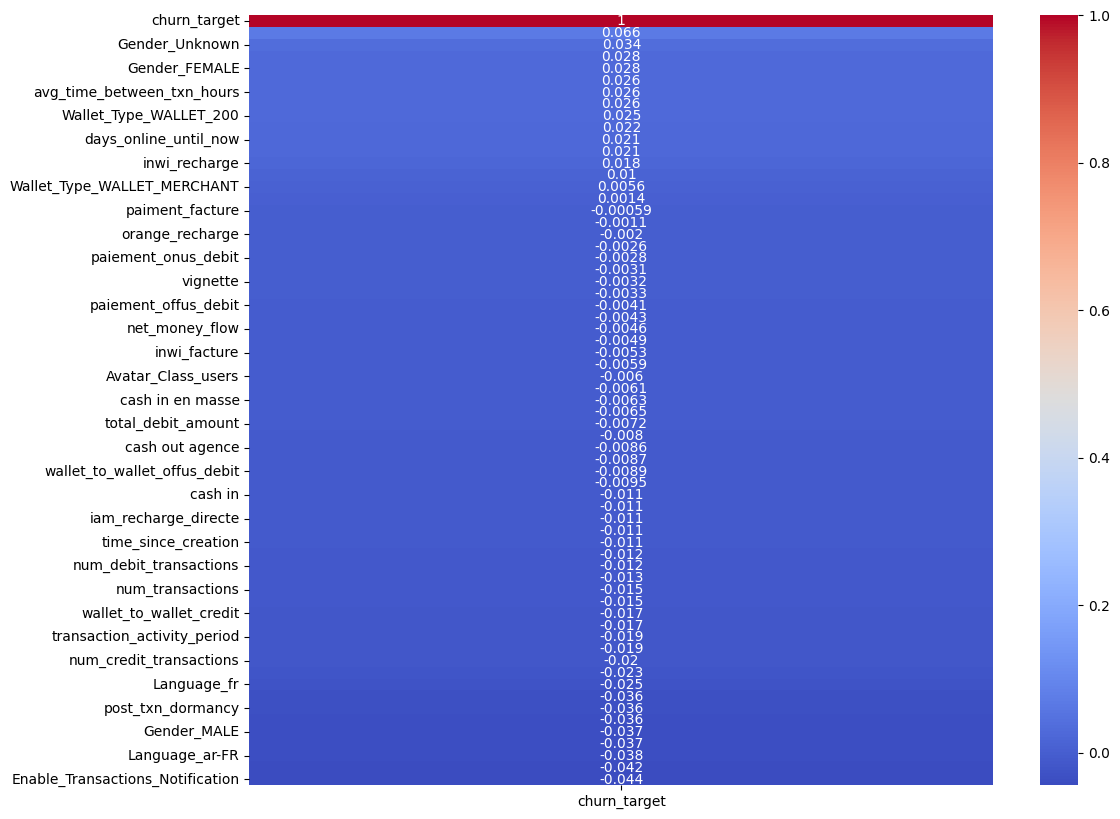

In [39]:


plt.figure(figsize=(12, 10))
sns.heatmap(data.corr(numeric_only=True)[['churn_target']].sort_values(by='churn_target', ascending=False), annot=True, cmap='coolwarm')


In [40]:
# Save the data to a CSV file
data.to_csv('Ora_Data.csv', index=False)

### Conclusion

The exploratory data analysis (EDA) provided valuable insights into the user and transaction datasets, enabling us to clean, preprocess, and engineer meaningful features. Key steps included handling missing values, encoding categorical variables, and creating new features such as transaction activity and churn indicators. These efforts have prepared the data for the next phase of the project.

### Next Steps

In the next phase, we will transition to machine learning, where we will build and evaluate predictive models to identify at-risk users. This phase will be documented in the `ML_phase.ipynb` notebook. The focus will be on selecting appropriate algorithms, optimizing model performance, and deriving actionable insights to reduce user churn.

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, make_scorer
import numpy as np
import pandas as pd

# 1. Split data
X = data.drop(columns=['churn_target', 'User_Id'])
y = data['churn_target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 2. Define Random Forest model with class_weight to handle imbalance
rf = RandomForestClassifier(class_weight='balanced', random_state=42)

# 3. Setup parameter grid for tuning
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

# Use F1 score as the metric
f1 = make_scorer(f1_score)

# 4. Grid Search with cross-validation
grid_search = GridSearchCV(
    rf,
    param_grid,
    scoring=f1,
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

# 5. Best model
best_rf = grid_search.best_estimator_

# 6. Evaluate on test data
y_pred = best_rf.predict(X_test)

from sklearn.metrics import classification_report, confusion_matrix

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# 7. Feature importance
importances = best_rf.feature_importances_
indices = np.argsort(importances)[::-1]

print("\nTop 10 Feature Importances:")
for i in range(10):
    print(f"{i+1}. {X.columns[indices[i]]}: {importances[indices[i]]:.4f}")

Fitting 5 folds for each of 72 candidates, totalling 360 fits

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.64      0.77      2470
           1       0.08      0.46      0.14       171

    accuracy                           0.63      2641
   macro avg       0.51      0.55      0.45      2641
weighted avg       0.89      0.63      0.73      2641


Confusion Matrix:
[[1593  877]
 [  93   78]]

Top 10 Feature Importances:
1. time_since_last_update: 0.1090
2. time_since_creation: 0.0944
3. account_duration: 0.0938
4. days_online_until_now: 0.0884
5. activity_duration: 0.0847
6. days_since_seen: 0.0807
7. post_txn_dormancy: 0.0786
8. Language_ar: 0.0587
9. Language_ar-FR: 0.0336
10. Enable_Transactions_Notification: 0.0222
